# Mori-Zwanzig effective dynamics and its RG flow

In `00_ising.ipynb` the system was static: we coarse-grained configurations and fitted a Hamiltonian. Here it
**evolves**. The fine dynamics is a deterministic PDE with random initial states. Coarse-graining it gives a
field whose evolution is no longer closed: it depends on the scales we threw away. The Mori-Zwanzig formalism
makes this exact. The coarse field follows a **generalized Langevin equation** with a Markov term, a memory and a
noise, and all three are fitted from the data.

The pipeline, every step from `src/core`:

1. **Simulate** an ensemble of trajectories (`PolynomialPDE`).
2. **Coarse-grain** them with a sharp spectral cutoff at block sizes 2, 4, 8, 16 (`coarse`).
3. **Fit** the Mori kernels of an operator basis at every scale (`MoriKernels`, through `KernelEnvironment`).
4. **Follow the kernels across scales**, the RG flow, and extrapolate them to a scale we never fit.
5. **Simulate the effective dynamics** at that scale and compare with the truth.
6. Look at **what it leaves out**, the noise.

`KernelEnvironment` (in `core.evaluation`) holds steps 2 to 5 for one dataset; `02_llm_pipeline.ipynb` uses the
same object to score the bases a language model proposes.

In [1]:
import sys

sys.path.append("../src")

import numpy as np

from core.data.polynomial_pde import PolynomialPDE
from core.evaluation.environment import Levels, coarse
from core.evaluation.kernels import KernelEnvironment
from core.operators.symbolic import SymbolicOperator
from models.mz_noise import orthogonal_noise, simulate
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#8a8984", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua: one per basis
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}  # one blue, light (fine) to dark (coarse)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "lines.markersize": 8, "legend.frameon": False,
})

## 1. The fine dynamics

The viscous Burgers equation on $[0, 2\pi)$ with $N = 128$ points,

$$ \partial_t u = -\tfrac12 \partial_x (u^2) + \nu\, \partial_x^2 u, \qquad \nu = 0.08 . $$

`PolynomialPDE` takes the right-hand side in the operator language of `core.operators.symbolic`. Here `D` is
$\partial_x$, and `D(u,2)` is $\partial_x^2 u$. It integrates the linear terms exactly and the nonlinear ones with
RK4, and records 21 snapshots $\Delta t = 0.05$ apart. Initial states are random fields whose energy peaks at
$k_0 = 3$.

`KernelEnvironment` simulates two independent ensembles: 200 **fit trajectories**, on which the kernels are fitted, and 100 **scoring trajectories**, on which the effective dynamics is
scored and which the fit never sees.
`Levels` sets the scales: we **fit** at levels 1-3 (block sizes 2, 4, 8) and **predict** at level 4 (block size 16, the **prediction scale**), which is
never fitted.

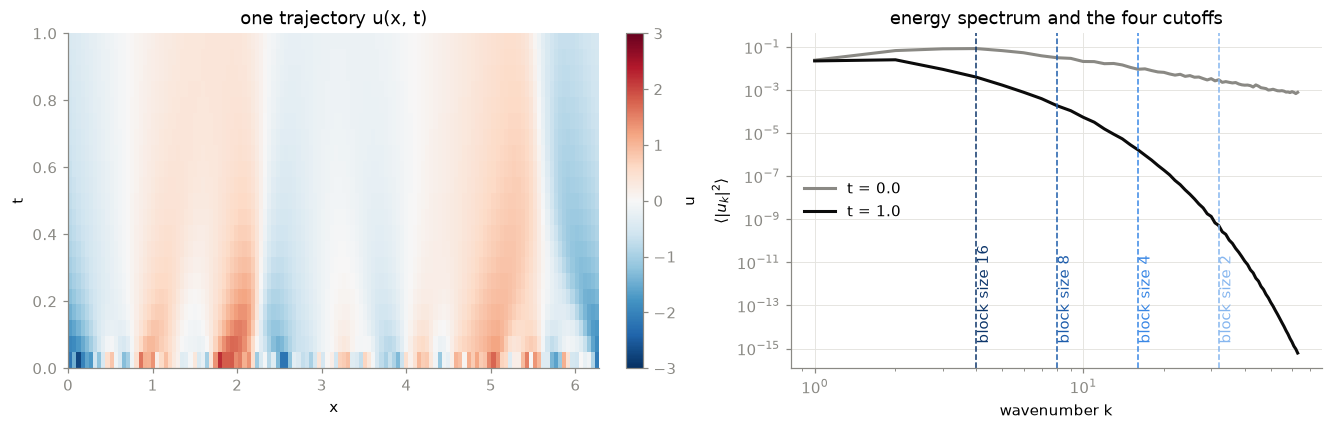

In [2]:
pde = PolynomialPDE("-0.5*D(u**2) + 0.08*D(u,2)", n=128)
LEVELS = Levels(fit=(1, 2, 3), predict=4, n_extrapolation_levels=3)
env = KernelEnvironment(pde, LEVELS, n_fit=200, n_score=100, seed=0, cost=0.0, n_lags=4)

fine, _ = pde.ensemble(seed=0, n_batch=200)  # the training ensemble at full resolution (the same seed)
times = pde.times

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
image = ax0.imshow(fine.values[0], aspect="auto", origin="lower", cmap="RdBu_r", vmin=-3, vmax=3,
                   extent=[0, pde.length, times[0], times[-1]])
ax0.set(xlabel="x", ylabel="t", title="one trajectory u(x, t)")
ax0.grid(False)
fig.colorbar(image, ax=ax0, label="u")

spectrum = np.mean(np.abs(np.fft.fft(fine.values, axis=-1, norm="forward")) ** 2, axis=0)
k = np.arange(1, pde.n // 2)
ax1.loglog(k, spectrum[0, 1:pde.n // 2], color=MUTED, label=f"t = {times[0]:.1f}")
ax1.loglog(k, spectrum[-1, 1:pde.n // 2], color=INK, label=f"t = {times[-1]:.1f}")
for level, color in LEVEL_COLORS.items():
    ax1.axvline(pde.n / 2 ** (level + 1), color=color, linewidth=1, linestyle="--")
    ax1.text(pde.n / 2 ** (level + 1), 1e-15, f" block size {2**level}", color=color, rotation=90, va="bottom")
ax1.set(xlabel="wavenumber k", ylabel=r"$\langle |u_k|^2 \rangle$", title="energy spectrum and the four cutoffs")
ax1.legend(loc="center left")
plt.show()

Burgers turns the random initial state into smooth ramps separated by steep **fronts**: the sharp drops from red
to blue, near $x \approx 2.3$ and $x \approx 5.6$ in this trajectory. The small-scale noise of the initial
state is damped within a few steps. The nonlinearity keeps pushing energy to high $k$, which viscosity drains. Every cutoff (dashed) cuts through the populated part of the
spectrum, so the coarse field always misses something.

## 2. Coarse-graining

Level $n$ keeps the modes $|k| < \pi / (2^n \Delta x)$ and stores them on a grid with one point per mode: 63, 31,
15 and 7 points. `coarse(field, level)` is the filter the environment applies.

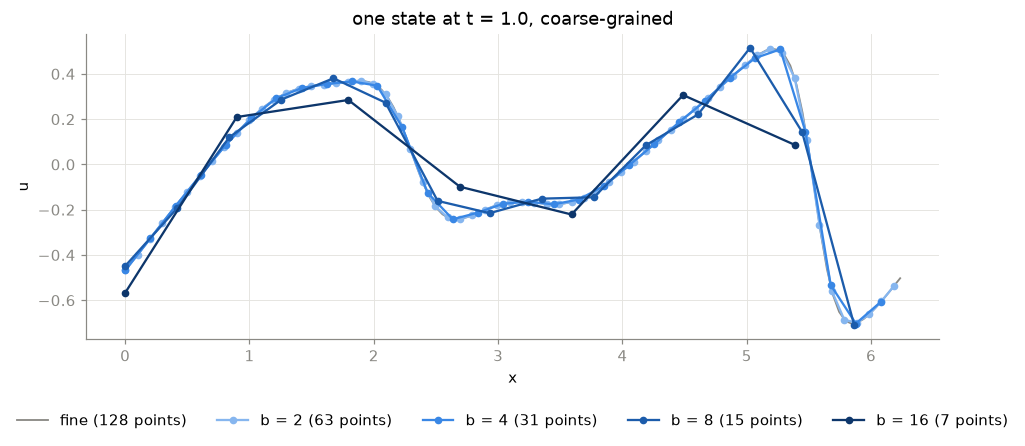

In [3]:
x = np.arange(pde.n) * pde.dx
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(x, fine.values[0, -1], color=MUTED, linewidth=1.2, label=f"fine ({pde.n} points)")
for level, color in LEVEL_COLORS.items():
    c = coarse(fine, level)
    xc = np.arange(c.spatial_shape[0]) * c.scale[0]
    ax.plot(xc, c.values[0, -1], "o-", color=color, markersize=4, linewidth=1.5,
            label=f"b = {2**level} ({c.spatial_shape[0]} points)")
ax.set(xlabel="x", ylabel="u", title=f"one state at t = {times[-1]:.1f}, coarse-grained")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()

## 3. The Mori-Zwanzig equation

Choose an **operator basis** $\{O_1, \dots, O_p\}$, nonlinear functions of the coarse field. The **observables**
are $g = (u, O_1(u), \dots, O_p(u))$, mode by mode on the coarse grid; $u$ itself is always included. Mori's
projection gives, exactly, for every wavevector $k$:

$$
g_k(t+1) \;=\; \underbrace{\Omega^{(0)}(k)\, g_k(t)}_{\text{Markov}}
\;+\; \underbrace{\sum_{l \ge 1} \Omega^{(l)}(k)\, g_k(t-l)}_{\text{memory}}
\;+\; \underbrace{W_k(t+1)}_{\text{noise}} .
$$

The kernels $\Omega^{(l)}$ are $(p+1) \times (p+1)$ matrices, computed from the two-time correlations
$C(n) = \langle g(n)\, g(0)^\dagger \rangle$ (`MoriKernels`, memory truncated to 4 lags). The noise $W$, the
**orthogonal dynamics**, is uncorrelated with the observables at time 0. It is what the basis cannot predict.

The first measure of a basis: **what fraction of the next step of $u$ does it leave unexplained?**

u alone      unexplained fraction at block sizes 2, 4, 8: 0.831, 0.810, 0.701
u, u²        unexplained fraction at block sizes 2, 4, 8: 0.210, 0.161, 0.201
u, u², u³    unexplained fraction at block sizes 2, 4, 8: 0.110, 0.065, 0.135


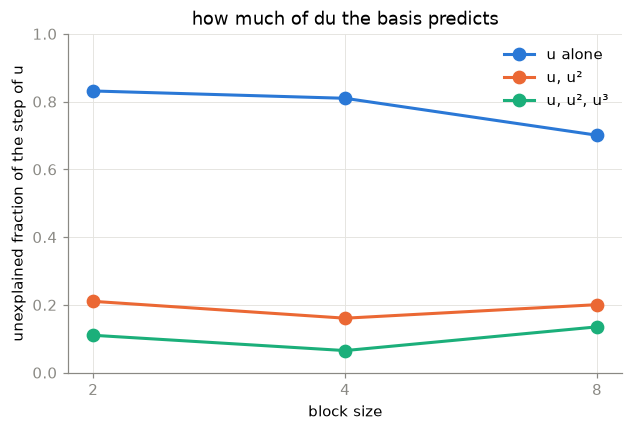

In [4]:
BASES = {"u alone": [], "u, u²": ["u**2"], "u, u², u³": ["u**2", "u**3"]}
bases = {name: [SymbolicOperator(text) for text in texts] for name, texts in BASES.items()}

fig, ax = plt.subplots(figsize=(6.5, 4))
for color, (name, ops) in zip(SERIES, bases.items()):
    unexplained = [env.one_step_residual(env.observable_ops(ops), n) for n in LEVELS.fit]
    ax.plot([2**n for n in LEVELS.fit], unexplained, "o-", color=color, label=name)
    print(f"{name:12s} unexplained fraction at block sizes 2, 4, 8: " + ", ".join(f"{r:.3f}" for r in unexplained))
ax.set(xscale="log", xlabel="block size", ylabel="unexplained fraction of the step of u", ylim=(0, 1),
       xticks=[2, 4, 8], xticklabels=[2, 4, 8], title="how much of du the basis predicts")
ax.minorticks_off()
ax.legend()
plt.show()

With $u$ alone the kernels are almost just viscous decay ($\Omega^{(0)}_{uu} \approx e^{-\nu k^2 \Delta t}$), and
80% of the step of $u$ is noise. **Adding $u^2$ explains most of it**. That is the Burgers nonlinearity: mode by
mode, $\partial_x(u^2)_k = ik\,(u^2)_k$ is proportional to the observable $(u^2)_k$. $u^3$ explains part of the
rest, which is generated by coarse-graining.

## 4. The RG flow of the kernels

The coarsest level keeps the wavevectors $|k| \le 3$, and they exist at every level. So every kernel entry at
those $k$ is a function of the scale: the **RG flow**. `env.flow(ops)` returns the kernels at those wavevectors
for every fit level. `env.extrapolated_kernels(ops)` extrapolates them linearly in the level to block size 16.

Take the Markov coupling of $u$ to $u^2$. If $u^2$ entered only through the bare equation, it would be
$-\tfrac{i k \Delta t}{2}$ per step.

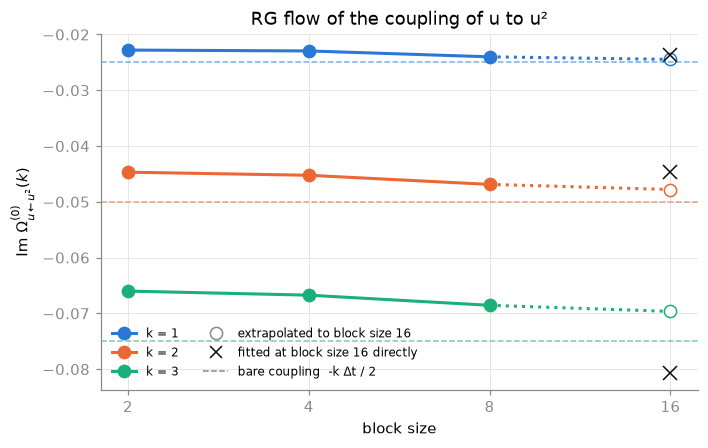

In [5]:
ops = bases["u, u²"]
flow = env.flow(ops)  # (fit level, lag, k, M, M) at the wavevectors of the prediction scale
extrapolated = env.extrapolated_kernels(ops).kernels
direct = env.kernels(env.observable_ops(ops), LEVELS.predict).kernels  # fitted at block size 16, for comparison only
fit_b, predict_b = [2**n for n in LEVELS.fit], 2**LEVELS.predict

fig, ax = plt.subplots(figsize=(7, 4.2))
for color, q in zip(SERIES, (1, 2, 3)):
    i = int(np.argmin(np.abs(env.k_predict - q)))
    ax.plot(fit_b, flow[:, 0, i, 0, 1].imag, "o-", color=color, label=f"k = {q}")
    ax.plot([fit_b[-1], predict_b], [flow[-1, 0, i, 0, 1].imag, extrapolated[0, i, 0, 1].imag], ":", color=color)
    ax.plot(predict_b, extrapolated[0, i, 0, 1].imag, "o", color=color, markerfacecolor="white")
    ax.plot(predict_b, direct[0, i, 0, 1].imag, "x", color=INK, markersize=9)
    ax.axhline(-q * pde.dt / 2, color=color, linewidth=1, linestyle="--", alpha=0.6)
ax.plot([], [], "o", color=MUTED, markerfacecolor="white", label="extrapolated to block size 16")
ax.plot([], [], "x", color=INK, label="fitted at block size 16 directly")
ax.plot([], [], "--", color=MUTED, linewidth=1, label="bare coupling  -k Δt / 2")
ax.set(xscale="log", xlabel="block size", ylabel=r"Im $\Omega^{(0)}_{u \leftarrow u^2}(k)$",
       xticks=[*fit_b, predict_b], xticklabels=[*fit_b, predict_b], title="RG flow of the coupling of u to u²")
ax.minorticks_off()
ax.legend(ncol=2, fontsize=8)
plt.show()

Each coupling sits close to its bare value: the flow **recovers the equation's own nonlinearity** from the data. The
unresolved scales renormalize it a little, more at larger $k$, and the flow drifts slowly with the block size.

At $k = 1$ and $2$ the extrapolation (open circles) lands close to what a fit at block size 16 would give (crosses),
without ever using data at that scale. At $k = 3$ it misses: $k = 3$ is the last mode kept at block size 16, right at
the cutoff, where the discarded scales act most strongly and the direct fit leaves the trend of the fit levels. A
linear extrapolation in the level cannot see that coming. This error is part of what the effective dynamics below pays.

## 5. The effective dynamics at the coarsest scale

The **effective dynamics** advances $u$ at block size 16 with the $u$ row of the extrapolated kernels, re-evaluating the operators
on the predicted $u$ at every step. It starts from the first 4 true states of the scoring trajectories and is
compared with the truth for the next 16 steps. `env.evaluate(ops)` returns that error, and the same error with
the directly fitted kernels.

basis           error, extrapolated  error, fitted at block size 16
u alone                      0.2340                          0.2340
u, u²                        0.1680                          0.1405
u, u², u³                    0.1686                          0.1326


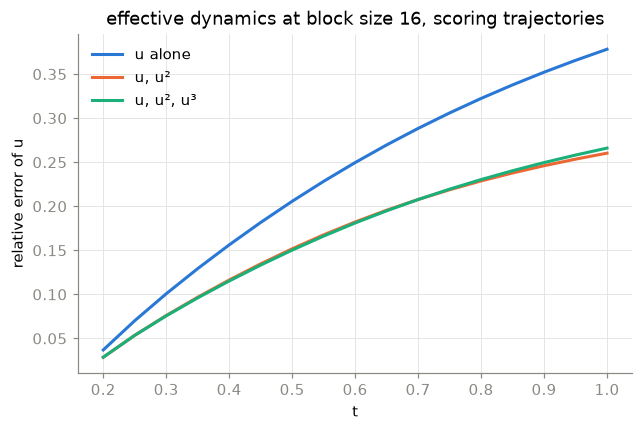

In [6]:
print(f"{'basis':14s} {'error, extrapolated':>20s} {'error, fitted at block size 16':>31s}")
for name, ops in bases.items():
    e = env.evaluate(ops)
    print(f"{name:14s} {e.error:20.4f} {e.direct_error:31.4f}")

test = env.u_score[LEVELS.predict]
h = 4
fig, ax = plt.subplots(figsize=(6.5, 4))
for color, (name, ops) in zip(SERIES, bases.items()):
    path = simulate(test, env.extrapolated_kernels(ops))[0]
    error = np.linalg.norm(path - test.values, axis=(0, 2)) / np.linalg.norm(test.values, axis=(0, 2))
    ax.plot(times[h:], error[h:], color=color, label=name)
ax.set(xlabel="t", ylabel="relative error of u", title="effective dynamics at block size 16, scoring trajectories")
ax.legend()
plt.show()

$u^2$ lowers the error at the coarse scale by about a quarter (0.234 to 0.168 on average over the 16 steps). $u^3$
adds nothing there. It helped the one-step prediction at the fit scales (section 3), but its contribution does not
survive the extrapolation to block size 16, and every step of the effective dynamics pays for evaluating it. **More operators are not automatically better**. The right basis is the one that
stays important along the flow, which is what the feedback in `02_llm_pipeline.ipynb` reports.

## 6. What the effective dynamics leaves out: the noise

The effective dynamics above has no noise. It drops $W$, so its trajectories are too smooth. The noise of $u$ under
the extrapolated kernels, on the training ensemble at block size 16 (`orthogonal_noise`), is far from white.

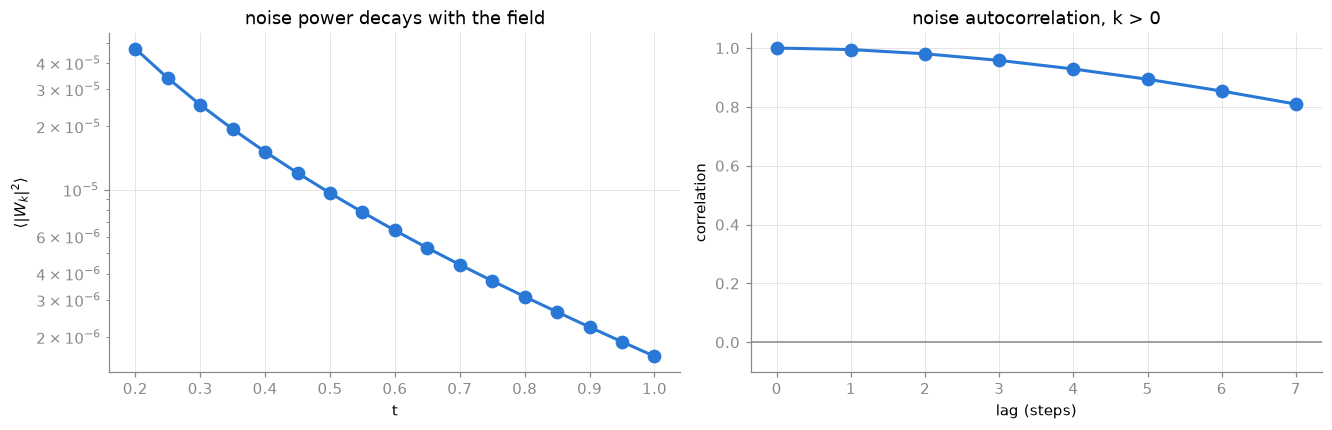

In [7]:
kernels = env.extrapolated_kernels(bases["u, u²"])
g, W = orthogonal_noise(env.u[LEVELS.predict], kernels)  # W: (batch, time, k)

power = np.mean(np.abs(W) ** 2, axis=(0, 2))
positive = env.k_predict[:, 0] > 0  # the wavenumbers along x of the modes
Wn = W[..., positive] / np.sqrt(np.mean(np.abs(W[..., positive]) ** 2, axis=0, keepdims=True))
lags = np.arange(8)
correlation = [np.mean(Wn[:, l:] * Wn[:, :Wn.shape[1] - l].conj()).real for l in lags]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
ax0.semilogy(times[h:], power, "o-", color=SERIES[0])
ax0.set(xlabel="t", ylabel=r"$\langle |W_k|^2 \rangle$", title="noise power decays with the field")
ax1.plot(lags, correlation, "o-", color=SERIES[0])
ax1.axhline(0, color=MUTED, linewidth=1)
ax1.set(xlabel="lag (steps)", ylabel="correlation", ylim=(-0.1, 1.05), title="noise autocorrelation, k > 0")
plt.show()

The noise is **strongly correlated in time**: one step later it is almost the same. Its size also decays as the
field loses energy. White noise cannot reproduce it. It needs a model with memory, whose distribution changes
in time. That is the stochastic recurrent network of `src/models` (`stochastic_rnn.py`, `mz_noise.py`), fitted in
`02_llm_pipeline.ipynb` on the basis a language model has learned to propose.

**Summary.** An operator basis turns a coarse-grained deterministic PDE into a closed stochastic equation at every
scale. The kernels of that equation flow with the scale, and their flow can be extrapolated to scales we never
fitted. How good the effective dynamics is there depends on the basis. Here we chose it by hand from the equation, which we
knew. Notebook 02 learns to choose it from the data.